<a href="https://colab.research.google.com/github/aminebadi3/PROJET-AAA/blob/main/MLPRO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Data exploration :

imports :

In [72]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

data loading :

In [73]:
import pandas as pd
data=pd.read_csv('diamonds.csv')

visualiazation of data :

In [74]:
data.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


data info :

In [75]:
data.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [76]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


separating labels and target :

In [77]:
X=data.drop(columns=['price'],axis=1)
Y=data['price']
X_train , X_test , Y_train , Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

categorical values :

In [78]:
cat_x=["cut", "color", "clarity"]

for col in cat_x :
    print(col, X[col].nunique(), X[col].unique().tolist())

cut 5 ['Ideal', 'Premium', 'Good', 'Very Good', 'Fair']
color 7 ['E', 'I', 'J', 'H', 'F', 'G', 'D']
clarity 8 ['SI2', 'SI1', 'VS1', 'VS2', 'VVS2', 'VVS1', 'I1', 'IF']


In [79]:
cut_order     = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
color_order   = ["J", "I", "H", "G", "F", "E", "D"]
clarity_order = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]

# On determinera par la suite l'influence des choix de OneHotEncoder et OrdinalEncoder pour voir

num_x = [c for c in X.columns if c not in cat_x ]

prep_ordinal = ColumnTransformer([
    ("num", StandardScaler(), num_x),
    ("cat", OrdinalEncoder(categories=[cut_order, color_order, clarity_order]), cat_x),
])

prep_onehot = ColumnTransformer([
    ("num", StandardScaler(), num_x),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_x),
])

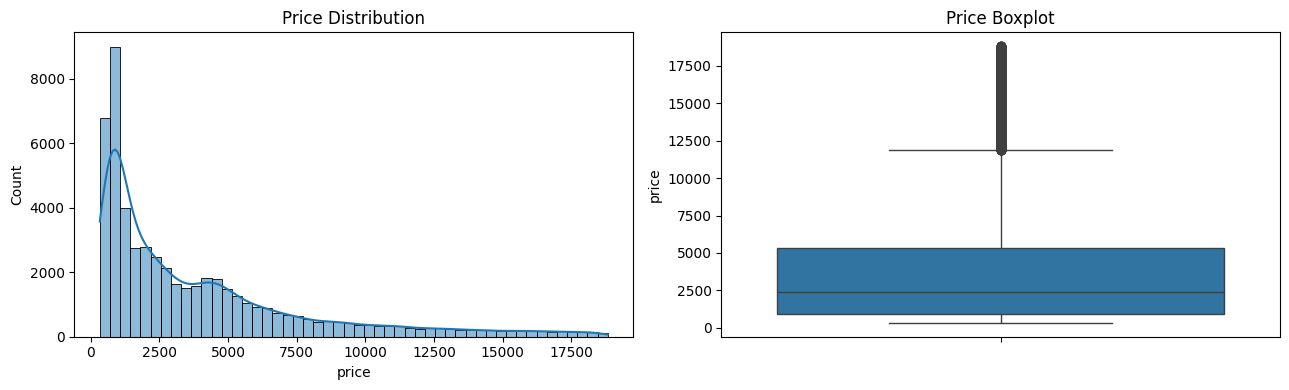

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(Y, bins=50, kde=True, ax=axes[0])
axes[0].set_title('Price Distribution')

sns.boxplot(Y, ax=axes[1])
axes[1].set_title('Price Boxplot')

plt.tight_layout()
plt.show()